### Tutorial 3: Integrative and generative analysis of spatial epigenome-transcriptome-proteome data (mouse brain tissue, P21S1)

In this tutorial, we demonstrate how to apply MultiGlue for integrative and generative analysis of spatial epigenome-transcriptome-proteome data. As an example, we analyze mouse brain data. This data comprised four coronal sections collected at distinct development stages (P0, P5, P10, P21). Each section simultaneously profiled the transcriptome, epigenome, and a large protein panel within the same tissue section. We use the P21 mouse brain as a representative example to demonstrate MultiGlue's capability for integrating and generating spatial triple-omics data. 

Before running the pipleline, please download the input data via https://drive.google.com/drive/folders/1qADGtpQo1Pkhu1MeUohuCBPxuD6yU5J6?usp=share_link.

# Loading package

In [31]:
import os
import torch
import pandas as pd
import scanpy as sc
import pickle
import numpy as np

In [32]:
import MultiGlue

In [33]:
# Environment configuration. MultiGlue pacakge can be implemented with either CPU or GPU. GPU acceleration is highly recommend for imporoved efficiency.
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# The location of R, which is required for the 'mclust' clustering algorithm. Please replace the path below with local R installation path
os.environ['R_HOME'] = '/home/andy/miniconda3/envs/MultiGlue/lib/R'

# Loading data

In [34]:
# Read data
file_fold = '/home/andy/miniconda3/work/MultiGlue/data/tri_omics/P21S1_05/' #please replace 'file_fold' with the download path

with open(file_fold + 'adj_gene_peak_adt.pkl','rb') as f:
    adj_graph = pickle.load(f) 
    
print(adj_graph.shape)

adata_omics1 = sc.read_h5ad(file_fold + 'rna.h5ad')
adata_omics2 = sc.read_h5ad(file_fold + 'atac.h5ad')
adata_omics3 = sc.read_h5ad(file_fold + 'P21S1_05_ADT.h5ad')

adata_omics1.var_names_make_unique()
adata_omics2.var_names_make_unique()
adata_omics3.var_names_make_unique()

adata_omics1.layers['counts'] = adata_omics1.X.copy()
adata_omics2.layers['counts'] = adata_omics2.X.copy()
adata_omics3.layers['counts'] = adata_omics3.X.copy()

print('RNA:', adata_omics1)
print('ATAC:', adata_omics2)
print('ADT:', adata_omics3)

(5445, 5445)
RNA: AnnData object with n_obs × n_vars = 8988 × 32285
    obs: 'array_row', 'array_col', 'in_tissue'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    obsm: 'spatial'
    layers: 'counts'
ATAC: AnnData object with n_obs × n_vars = 8988 × 16040
    obs: 'array_row', 'array_col', 'in_tissue'
    var: 'chrom', 'chromStart', 'chromEnd', 'highly_variable'
    obsm: 'spatial'
    layers: 'counts'
ADT: AnnData object with n_obs × n_vars = 8988 × 145
    obs: 'array_row', 'array_col', 'in_tissue'
    obsm: 'spatial'
    layers: 'counts'


In [35]:
from MultiGlue.preprocess import fix_seed
# Setting random seed
random_seed = 2022
fix_seed(random_seed)

# Specifying input data type
data_type = 'Spatial-transcriptome-epigenome-proteome'

# Pre-processing data

In [36]:
# Construct graph
from MultiGlue.preprocess import construct_neighbor_graph
adata_omics1, adata_omics2, adata_omics3 = construct_neighbor_graph(adata_omics1, adata_omics2, adata_omics3, datatype=data_type)

In [37]:
from MultiGlue.preprocess import neighbor_context_features, permutation, clr_normalize_each_cell, lsi, pca

# RNA
#sc.pp.filter_genes(adata_omics1, min_cells=10)
#sc.pp.filter_cells(adata_omics1, min_genes=200)
#if 'highly_variable' not in adata_omics1.obs:
#   sc.pp.highly_variable_genes(adata_omics1, flavor="seurat_v3", n_top_genes=3000)
sc.pp.normalize_total(adata_omics1, target_sum=1e4)
sc.pp.log1p(adata_omics1)
sc.pp.scale(adata_omics1)

adata_omics1 =  adata_omics1[:, adata_omics1.var['highly_variable']]
adata_omics1.obsm['feat'] = pca(adata_omics1, n_comps=50)
  
adata_omics1.obsm['feat_a'] = permutation(adata_omics1.obsm['feat'].copy())
  
# ATAC
adata_omics2 = adata_omics2[adata_omics1.obs_names].copy() # .obsm['X_lsi'] represents the dimension reduced feature
if 'X_lsi' not in adata_omics2.obsm.keys():
    #if 'highly_variable' not in adata_omics2.obs: 
    #   sc.pp.highly_variable_genes(adata_omics2, flavor="seurat_v3", n_top_genes=3000)   # masked for real triplet omics datasets
    lsi(adata_omics2, use_highly_variable=False, n_components=51)  
  
adata_omics2 =  adata_omics2[:, adata_omics2.var['highly_variable']]  
adata_omics2.obsm['feat'] = adata_omics2.obsm['X_lsi'].copy()
  
adata_omics2.obsm['feat_a'] = permutation(adata_omics2.obsm['feat'].copy())
  
# ADT
adata_omics3 = clr_normalize_each_cell(adata_omics3)
adata_omics3.obsm['feat'] = pca(adata_omics3, n_comps=50)
  
adata_omics3.obsm['feat_a'] = permutation(adata_omics3.obsm['feat'].copy())

# obtain contextual feature matrices
adata_omics1.obsm['feat_context'] = neighbor_context_features(adata_omics1)
adata_omics2.obsm['feat_context'] = neighbor_context_features(adata_omics2)
adata_omics3.obsm['feat_context'] = neighbor_context_features(adata_omics3)
  
data = {'adata_omics1': adata_omics1, 'adata_omics2': adata_omics2, 'adata_omics3': adata_omics3, 'adj_graph': adj_graph} 

/home/andy/miniconda3/envs/MultiGlue/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/tmp/ipykernel_382136/1177828657.py:13: ImplicitModificationWarning: Setting element `.obsm['feat']` of view, initializing view as actual.
  adata_omics1.obsm['feat'] = pca(adata_omics1, n_comps=50)
/tmp/ipykernel_382136/1177828657.py:25: ImplicitModificationWarning: Setting element `.obsm['feat']` of view, initializing view as actual.
  adata_omics2.obsm['feat'] = adata_omics2.obsm['X_lsi'].copy()


# Training MulitGlue model

In [38]:
# Define MultiGlue model
from MultiGlue.train import Train_MultiGlue_3M
model = Train_MultiGlue_3M(data, datatype=data_type, device=device)

# Train model
print('Starting training...')
output = model.train()

Starting training...


100%|████████████████████████████████████████████████████████████████████████████| 3000/3000 [01:57<00:00, 25.60it/s]

Model training finished!



# Downstream analysis

After model training, MultiGlue will output integrated representations that preserve features of different molecular profiles and spatial information. Meanwhile, it also can generate spatially and biologically coherent molecular profiles. 

In [39]:
adata = adata_omics1.copy()
adata.obsm['MultiGlue'] = output['MultiGlue']
adata.obsm['pred_omics1'] = output['pred_omics1']
adata.obsm['pred_omics2'] = output['pred_omics2']
adata.obsm['pred_omics3'] = output['pred_omics3']

In [43]:
# we set 'mclust' as clustering tool by default. Users can also select 'leiden' and 'louvain'
from MultiGlue.utils import clustering
num_cluster = 18
tool = 'mclust' # mclust, leiden, and louvain
clustering(adata, key='MultiGlue', add_key='MultiGlue', n_clusters=num_cluster, method=tool, use_pca=True)
clustering(adata, key='pred_omics1', add_key='Omics1_pred', n_clusters=num_cluster, method=tool, use_pca=True)
clustering(adata, key='pred_omics2', add_key='Omics2_pred', n_clusters=num_cluster, method=tool, use_pca=True)
clustering(adata, key='pred_omics3', add_key='Omics3_pred', n_clusters=num_cluster, method=tool, use_pca=True)

fitting ...
  |======================================================================| 100%
fitting ...
  |======================================================================| 100%
fitting ...
  |======================================================================| 100%
fitting ...
  |======================================================================| 100%


In [44]:
# visualization
import matplotlib.pyplot as plt

adata.obsm['spatial'] = np.rot90(np.rot90(np.rot90(np.array(adata.obsm['spatial'])).T).T).T #P21S1
adata.obsm['spatial'][:,1] = -1*adata.obsm['spatial'][:,1]

AnnData object with n_obs × n_vars = 8988 × 3000
    obs: 'array_row', 'array_col', 'in_tissue', 'mclust', 'MultiGlue', 'Omics1_pred', 'Omics2_pred', 'Omics3_pred'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'adj_spatial', 'log1p', 'neighbors', 'umap', 'MultiGlue_colors', 'Omics1_pred_colors', 'Omics2_pred_colors', 'Omics3_pred_colors'
    obsm: 'spatial', 'feat', 'feat_a', 'feat_context', 'label_CSL', 'MultiGlue', 'pred_omics1', 'pred_omics2', 'pred_omics3', 'MultiGlue_pca', 'pred_omics1_pca', 'pred_omics2_pca', 'pred_omics3_pca', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'


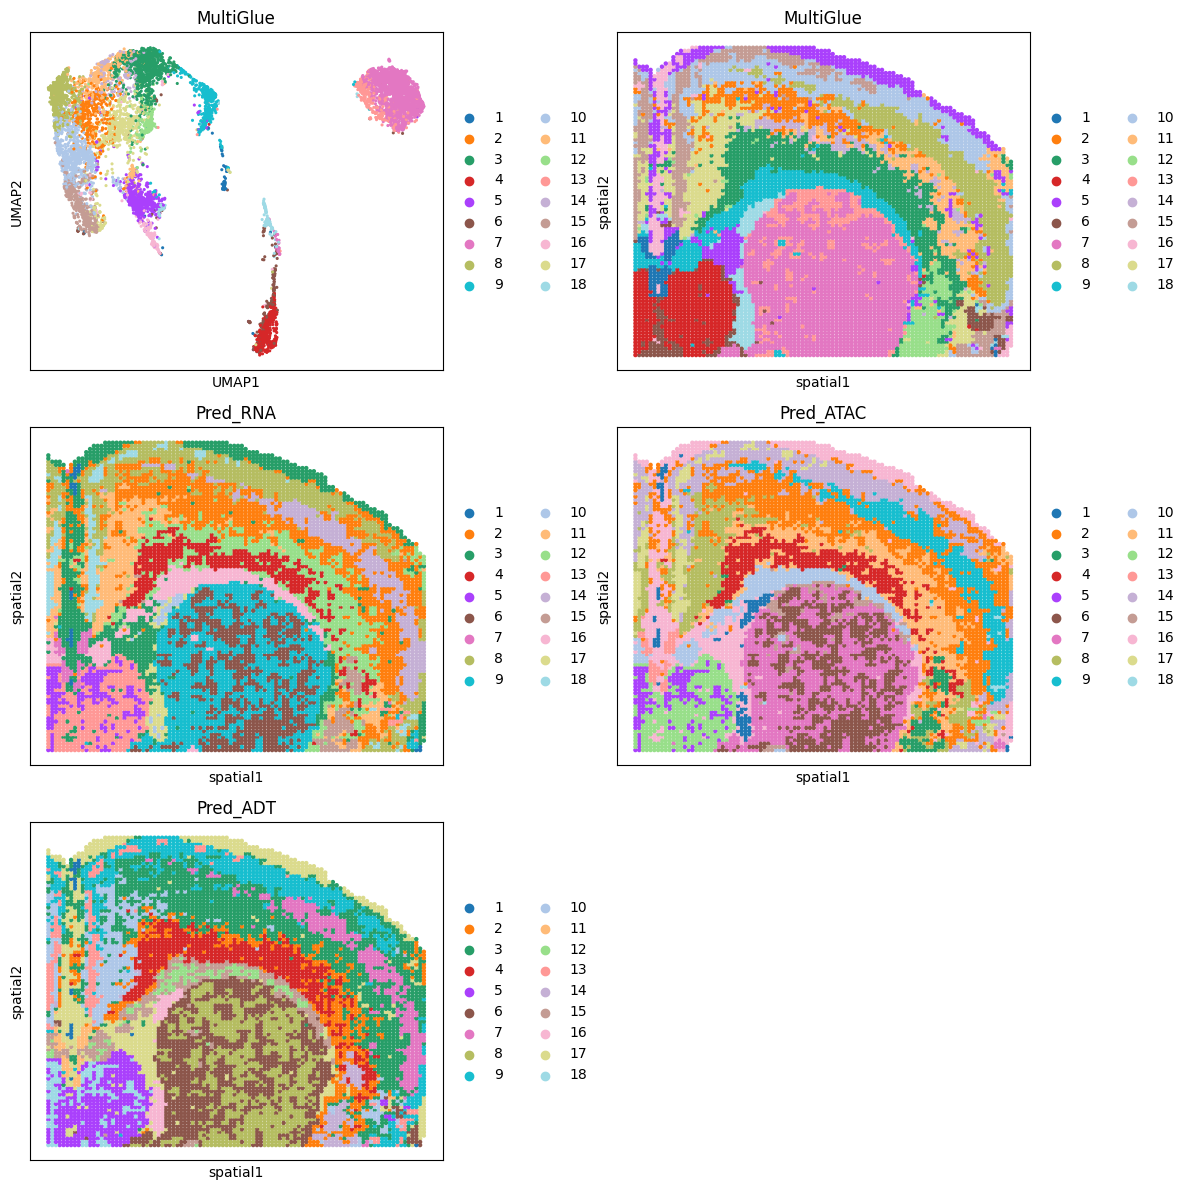

In [46]:
res = 40 #40

fig, ax_list = plt.subplots(3, 2, figsize=(12, 12))
sc.pp.neighbors(adata, use_rep='MultiGlue', n_neighbors=30)
sc.tl.umap(adata, min_dist=0.02)

sc.pl.umap(adata, color='MultiGlue', ax=ax_list[0, 0], title='MultiGlue', s=20, show=False)
sc.pl.embedding(adata, basis='spatial', color='MultiGlue', ax=ax_list[0, 1], title='MultiGlue', s=res, show=False)

sc.pl.embedding(adata, basis='spatial', color='Omics1_pred', ax=ax_list[1, 0], title='Pred_RNA', s=res, show=False)
sc.pl.embedding(adata, basis='spatial', color='Omics2_pred', ax=ax_list[1, 1], title='Pred_ATAC', s=res, show=False)
sc.pl.embedding(adata, basis='spatial', color='Omics3_pred', ax=ax_list[2, 0], title='Pred_ADT', s=res, show=False)

print(adata)

ax_list[2,1].axis('off')

plt.tight_layout(w_pad=0.3)
plt.show()